# The basic jump equation: simulated data

This notebook builds up the model in *Basic Jump Equation* one step at a time, on simulated
data only, so that every parameter is known and every estimate can be checked against the
truth. The notes split each trading day into the overnight jump and the cumulative intraday
return (CIDR) curve,

$$
J_t = P_t(0) - P_{t-1}(1), \qquad X_t(s) = P_t(s) - P_t(0), \qquad P_t(s) = 100\log S_t(s),
$$

and take geometric Brownian motion with i.i.d. overnight jumps as the starting point. The GBM is
a special case of the **null model**

$$
J_t = \alpha + \eta_t, \quad \eta_t \overset{\text{iid}}{\sim} N(0, \sigma_\eta^2), \qquad
X_t(s) = \mu(s) + \sigma_\varepsilon W_t(s), \quad \mu(0) = 0,
$$

with $\{W_t\}$ i.i.d. standard Brownian motions and $\{J_t\}$ independent of $\{X_t\}$: the
hypothesis that overnight jumps cannot be predicted from intraday returns. The **basic model**
then adds the research hypothesis $J_t = \alpha + \int_0^1 \beta(u) X_{t-1}(u)\,\mathrm{d}u +
\eta_t$.

| section | what it does |
|---|---|
| 1 | simulates three months of one-minute GBM prices |
| 2 | slices the path into jumps and curves, and plots both |
| 3 | fits the null model, with exact intervals, and holds it against the truth |
| 4 | plots the fitted model against the data |
| 5 | tests each assumption of the null, and measures the fit |
| 6 | says what this establishes, and what the basic model has to do next |

The code lives in `jump.basic_dgp` (the simulator and the slicing) and `jump.basic_est` (the
fit and the diagnostics); `tests/test_basic_jump.py` checks both, and says in each test what
it protects. The basic model itself is not fitted here: this notebook stops at the null, and
the next step tests $\beta = 0$ against it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

from fts_research.core import style
from fts_research.far.far_est import acf_norms
from fts_research.jump import basic_dgp as bd
from fts_research.jump import basic_est as be

style.use(plt)
pd.set_option("display.width", 120)
UP, DOWN, FIT = style.CATEGORICAL   # a jump's direction, and the fitted model; the truth is ink

## 1. A three-month GBM price path

*Notes, page 4.* The price follows $\mathrm{d}S = \nu S\,\mathrm{d}\tau + \sigma S\,\mathrm{d}B_\tau$,
so $S(\tau) = S_0 \exp(m\tau + \sigma B_\tau)$ with $m = \nu - \sigma^2/2$. One trading session
is one unit of time, the night has length $T$, and session $t$ runs over $[a_t, a_t + 1]$ with
$a_t = t(1+T) - 1$, so $S_t(s) = S(a_t + s)$. `bd.gbm_sessions` simulates the path exactly at
the grid points (Gaussian increments of $\log S$), so there is no discretisation error in the
prices, only in what is later computed from them.

| parameter | value | why |
|---|---|---|
| days | 63 | a quarter of a 252-day trading year |
| grid | 391 points | one-minute bars over a 6.5-hour session, plus the open; every fifth point gives the 79-point five-minute grid of the other notebooks |
| $S_0$ | 100 | the close before day 1, so $P_0(1)$ exists and $J_1$ is defined |
| $\sigma$ | 0.01 | a session standard deviation of $100\sigma = 1\%$ |
| $T$ | 0.25 | an overnight standard deviation of $100\sigma\sqrt{T} = 0.5\%$, half a session's, as in `jump_equation_v2`; the night then carries $T/(1+T) = 20\%$ of the day's variance |
| $\nu$ | $2.5\times10^{-4}$ | expected price growth of about 8% a year: $\mathrm{E}\,S(\tau) = S_0 e^{\nu\tau}$, and a year is $252(1+T) = 315$ units of $\tau$, so $315\nu \approx 0.079$. The expected *log* return is lower, $315m \approx 0.063$, because $m = \nu - \sigma^2/2$ |
| seed | 0 | fixes the path, so every number below reproduces |

Together these give a close-to-close standard deviation of $100\sigma\sqrt{1+T} \approx 1.12\%$
a day, or about 17.7% a year.

**$T$ is variance time, not clock time.** The GBM uses the same $\sigma$ through the night, so
the night's length sets its share of the variance. The clock-time ratio $17.5/6.5 \approx 2.7$
would put 73% of each day's variance into the hours when nothing trades. $T$ is therefore set
by the overnight variance it should produce. Weekends and holidays are left out, as in the
notes, so every night has the same $T$ and the null model's $J_t$ really is i.i.d.

In [2]:
rng = np.random.default_rng(0)

n_days = 63                      # three months of trading days
n_bars = 390                     # one-minute bars in a 6.5-hour session
S0 = 100.0                       # price at tau = 0, the close before day 1
sigma = 0.01                     # per session: a 1% session standard deviation
T = 0.25                         # the night, in variance time: a 0.5% overnight standard deviation
nu = 2.5e-4                      # drift per session unit: expected price growth of about 8% a year

path = bd.gbm_sessions(n_days=n_days, n_bars=n_bars, S0=S0, sigma=sigma, T=T, nu=nu, rng=rng)
S, s, a, tau, m = path["S"], path["s"], path["a"], path["tau"], path["m"]

dates = pd.bdate_range("2026-01-05", periods=n_days)   # labels only: the model has no weekends
prices = pd.DataFrame(S, index=pd.Index(dates, name="date"),
                      columns=pd.Index(np.round(s, 6), name="s"))

print(f"S has shape {S.shape}: {n_days} sessions x {n_bars + 1} grid points")
print(f"first open {S[0, 0]:.2f}, last close {S[-1, -1]:.2f}, "
      f"range {S.min():.2f} to {S.max():.2f}")
print(f"a year of {252 * (1 + T):.0f} time units: expected price growth {252 * (1 + T) * nu:.3f}, "
      f"expected log return {252 * (1 + T) * m:.3f}")
prices.iloc[:5, [0, 1, 2, -2, -1]].round(3)

S has shape (63, 391): 63 sessions x 391 grid points
first open 100.07, last close 109.18, range 94.48 to 111.69
a year of 315 time units: expected price growth 0.079, expected log return 0.063


s,0.000000,0.002564,0.005128,0.997436,1.000000
date,,,,,
2026-01-05,100.068,100.061,100.094,99.269,99.309
2026-01-06,99.076,99.065,99.036,99.142,99.056
2026-01-07,98.490,98.561,98.553,97.476,97.565
2026-01-08,97.031,97.008,96.961,97.838,97.898
2026-01-09,98.450,98.470,98.458,96.825,96.831


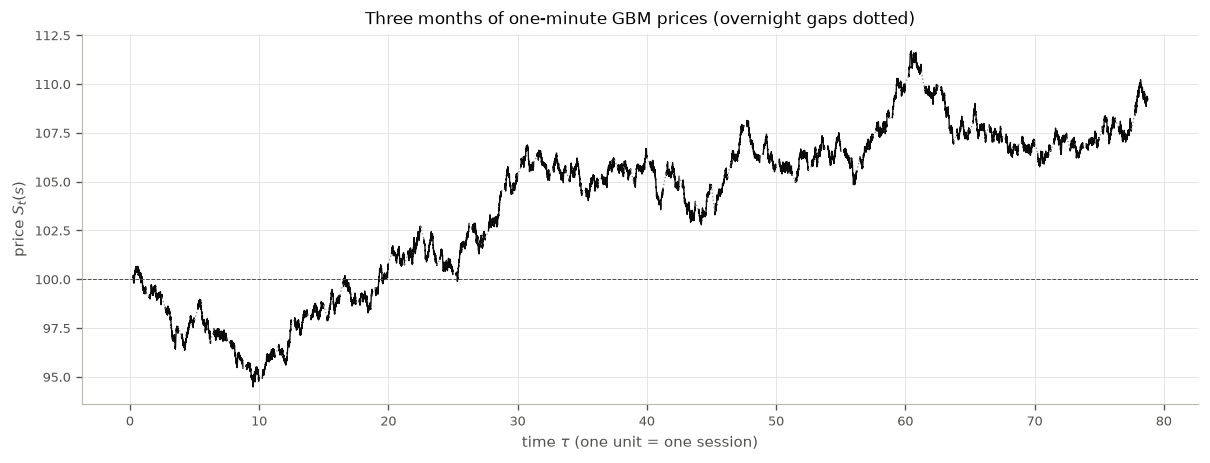

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
for t in range(n_days):
    ax.plot(tau[t], S[t], color=style.INK, lw=0.8)
    if t:
        ax.plot([tau[t - 1, -1], tau[t, 0]], [S[t - 1, -1], S[t, 0]],
                color=style.CONTROL, lw=0.8, ls=":")
ax.axhline(S0, color=style.MUTED, lw=0.6, ls="--")
ax.set_title("Three months of one-minute GBM prices (overnight gaps dotted)")
ax.set_xlabel(r"time $\tau$ (one unit = one session)")
ax.set_ylabel(r"price $S_t(s)$")
style.save_figure(fig, "basic_jump_price_path")
plt.show()

The arrays this leaves for what follows:

- `S`, shape `(63, 391)`: the raw price $S_t(s)$, a row per session and a column per grid point;
- `prices`: the same as a DataFrame, indexed by (label) date and by $s$;
- `s`, `a`, `tau`: the within-session grid, the session start times $a_t$ and the calendar time
  of every observation;
- `S0`: the close before day 1.

## 2. Slicing the path into jumps and curves

*Notes, page 1.* Each day contributes a pair $(J_t, X_t)$, in the order
$\mathcal F_{t-1} \to J_t \to X_t$: the jump forms overnight, and the session follows it. On the
percent log price $P = 100\log S$,

- $J_t = P_t(0) - P_{t-1}(1)$ is the move from yesterday's close to today's open, with
  $P_0(1) = 100\log S_0$ so that the first day has a jump too;
- $X_t(s) = P_t(s) - P_t(0)$ is the return since the open, so every curve starts at zero.

`bd.split_sessions` does both. The two pieces partition the log price, so adding them back up
must rebuild every close exactly, $P_t(1) = P_0(1) + \sum_{u \le t} (J_u + X_u(1))$; the cell
prints the largest error in that identity, which should be rounding. `tests/test_basic_jump.py`
also checks that the same prices, written as one-minute bars and passed through
`fdaSP.intraday.session_curves(anchor="open")` and `overnight_jumps` -- the route market data
will take -- give the same pairs.

In [4]:
J, X = bd.split_sessions(S, S0)
grid = s                                                # the session grid, s in [0, 1]

P = 100 * np.log(S)
rebuilt = 100 * np.log(S0) + np.cumsum(J + X[:, -1])
print(f"{J.size} jumps and {X.shape[0]} curves on {grid.size} grid points")
print(f"largest error in rebuilding the closes: {np.abs(rebuilt - P[:, -1]).max():.1e}")
print(f"curves start at zero: {np.all(X[:, 0] == 0)}")
print(f"jumps:           mean {J.mean():+.3f}%, sd {J.std(ddof=1):.3f}%")
print(f"session returns: mean {X[:, -1].mean():+.3f}%, sd {X[:, -1].std(ddof=1):.3f}%")

63 jumps and 63 curves on 391 grid points
largest error in rebuilding the closes: 0.0e+00
curves start at zero: True
jumps:           mean +0.039%, sd 0.449%
session returns: mean +0.101%, sd 0.979%


The curves are plotted **tail to head**: session $t$ occupies $[t-1, t]$ on a common axis,
so the sequence reads like the price chart with the overnight moves taken out. Each curve
starts at zero by construction, so at every open the line drops from yesterday's session
return back to zero (dotted). The jump that sits in that gap is the subject of the next
figure.

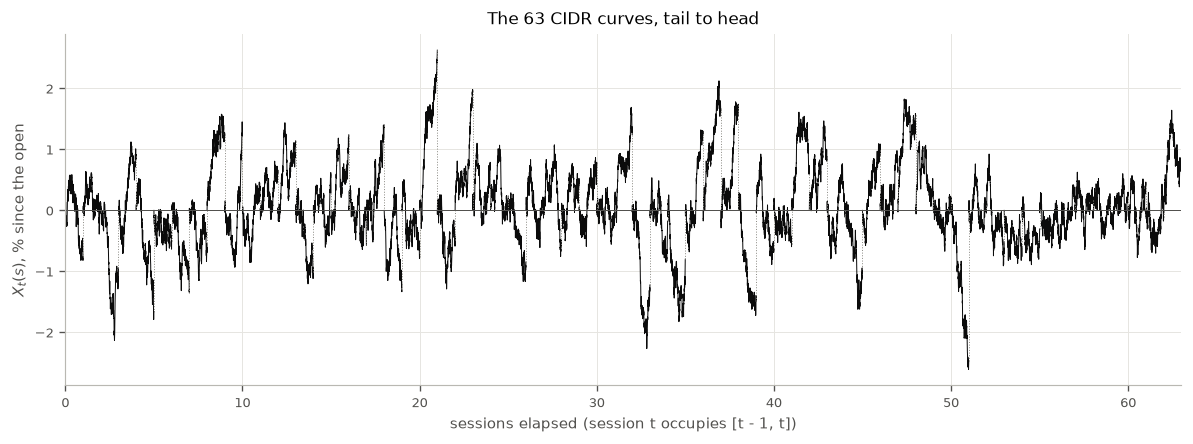

In [5]:
def tail_to_head(ax, curves, grid, color=style.INK):
    # Session t on [t - 1, t], with a dotted drop back to zero at each open.
    for t, x in enumerate(curves):
        ax.plot(t + grid, x, color=color, lw=0.6)
        if t:
            ax.plot([t, t], [curves[t - 1, -1], 0.0], color=style.CONTROL, lw=0.6, ls=":")
    ax.axhline(0, color=style.MUTED, lw=0.6)
    ax.set_xlim(0, len(curves))


fig, ax = plt.subplots(figsize=(12, 3.8))
tail_to_head(ax, X, grid)
ax.set_title("The 63 CIDR curves, tail to head")
ax.set_xlabel("sessions elapsed (session t occupies [t - 1, t])")
ax.set_ylabel(r"$X_t(s)$, % since the open")
style.save_figure(fig, "basic_jump_curves")
plt.show()

Every curve starts at zero and wanders the way a Brownian motion does: its spread grows
through the session, and the session's return at the close comes out positive or negative
with no visible pattern from one day to the next. Under the null nothing carries across a
dotted line, neither the level a session ended at nor its shape. Section 5 tests that, and the
basic model is the hypothesis that the jump in the gap is predictable from the curve before
it.

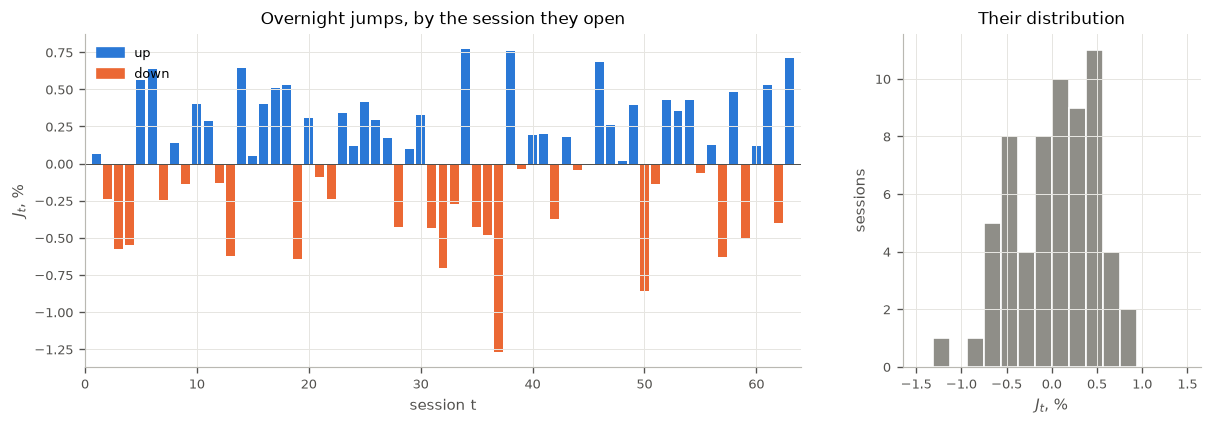

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6),
                               gridspec_kw={"width_ratios": [2.4, 1]})
day = np.arange(1, n_days + 1)
ax1.bar(day, J, color=np.where(J >= 0, UP, DOWN), width=0.8)
ax1.axhline(0, color=style.MUTED, lw=0.6)
ax1.set_xlim(0, n_days + 1)
ax1.set_title("Overnight jumps, by the session they open")
ax1.set_xlabel("session t")
ax1.set_ylabel(r"$J_t$, %")
ax1.legend(handles=[Patch(color=UP, label="up"), Patch(color=DOWN, label="down")], loc="upper left")

edge = np.ceil(np.abs(J).max() * 4) / 4                 # symmetric bins, a quarter-percent edge
ax2.hist(J, bins=np.linspace(-edge, edge, 17), color=style.CONTROL, edgecolor=style.SURFACE)
ax2.set_title("Their distribution")
ax2.set_xlabel(r"$J_t$, %")
ax2.set_ylabel("sessions")
style.save_figure(fig, "basic_jump_jumps")
plt.show()

The jumps are about half the size of the session returns (standard deviations 0.449% against
0.979% in the printout above), which is what the design asked for: $T = 0.25$ gives the night a
quarter of a session's variance. Up and down moves alternate without visible runs, and the
histogram is a rough bell with one large fall in the late thirties. The sample mean, +0.039%,
is eight times the true $\alpha = 100mT = 0.005\%$. That is noise, and section 3 shows how
much.

## 3. Fitting the null model

*Notes, pages 2, 3 and 9.* The null model is fitted exactly as written: $\alpha$ and
$\sigma_\eta$ for the jumps, and for the curves a mean $\mu(s)$ left free apart from
$\mu(0) = 0$, with one volatility $\sigma_\varepsilon$. The GBM's own restrictions -- $\mu$
linear in $s$, and $\sigma_\eta^2 = T\sigma_\varepsilon^2$ -- are not imposed; section 5 tests
the first, and the table below reports the second.

**The likelihood is exact on the grid.** A curve observed at $0 = s_0 < \dots < s_K = 1$
carries the same information as its $K$ increments, and under the null those are independent:

$$
\Delta X_{t,k} = X_t(s_k) - X_t(s_{k-1}) \sim N\big(\Delta\mu_k,\ \sigma_\varepsilon^2\,\Delta s_k\big),
$$

because Brownian motion has independent Gaussian increments with variance equal to the time
elapsed. So the curve equation is $K$ normal means sharing one variance, the jump equation is
one normal mean with its own, and the maximum likelihood estimators are closed-form:

| quantity | estimator | exact distribution |
|---|---|---|
| $\alpha$ | $\hat\alpha = \bar J$ | $(\hat\alpha - \alpha)/(s_\eta/\sqrt n) \sim t_{n-1}$ |
| $\sigma_\eta^2$ | $s_\eta^2 = \sum_t (J_t - \bar J)^2/(n-1)$ | $(n-1)s_\eta^2/\sigma_\eta^2 \sim \chi^2_{n-1}$ |
| $\mu(s)$ | $\hat\mu(s) = \bar X(s)$, the mean curve | $(\hat\mu(s) - \mu(s))/(s_\varepsilon\sqrt{s/n}) \sim t_{(n-1)K}$ |
| $\sigma_\varepsilon^2$ | $s_\varepsilon^2 = \sum_{t,k} (\Delta X_{t,k} - \Delta\hat\mu_k)^2/\Delta s_k \,/\, (n-1)K$ | $(n-1)K\,s_\varepsilon^2/\sigma_\varepsilon^2 \sim \chi^2_{(n-1)K}$ |
| $\sigma_\eta^2/\sigma_\varepsilon^2$ | $s_\eta^2/s_\varepsilon^2$ | $F_{n-1,\,(n-1)K}$ about the truth |

$s_\varepsilon^2$ is realised variance pooled over days, each increment scaled by its own
length. The variances use the unbiased divisors; the maximum likelihood versions (divisors $n$
and $nK$) enter only the log-likelihoods in section 5. Every interval below is therefore exact
at any sample size, not asymptotic -- `tests/test_basic_jump.py` measures each one's coverage
over 500 replications.

| setting | value | why |
|---|---|---|
| `level` | 0.95 | the conventional coverage, used for every interval and band |
| truth | `bd.gbm_null_parameters(sigma, T, nu)` | pages 8-9: $\alpha = 100mT$, $\sigma_\eta = 100\sigma\sqrt T$, $\mu(s) = 100ms$, $\sigma_\varepsilon = 100\sigma$ |

In [7]:
fit = be.fit_null(J, X, grid, level=0.95)
truth = bd.gbm_null_parameters(sigma=sigma, T=T, nu=nu)
table = be.parameter_table(fit, truth)

print(f"n = {fit['n']} days, K = {fit['K']} increments a day: "
      f"{fit['df_eta']} degrees of freedom for the jumps, {fit['df_eps']} for the curves")
print(f"relative standard error of sigma_eps: {100 * table.loc['sigma_eps', 'se'] / fit['sigma_eps']:.2f}%")
print(f"t-statistics against zero: alpha {fit['alpha'] / fit['alpha_se']:.2f}, "
      f"mu(1) {fit['mu'][-1] / fit['mu_se'][-1]:.2f}")
print(f"days needed for the true mu(1) to be twice its standard error: "
      f"{(2 * truth['sigma_eps'] / truth['drift']) ** 2:,.0f}")
table.round(4)

n = 63 days, K = 390 increments a day: 62 degrees of freedom for the jumps, 24180 for the curves
relative standard error of sigma_eps: 0.45%
t-statistics against zero: alpha 0.68, mu(1) 0.80
days needed for the true mu(1) to be twice its standard error: 10,000


,estimate,se,lower,upper,truth,covered
alpha,0.0386,0.0565,-0.0744,0.1516,0.005,True
sigma_eta,0.4487,0.0403,0.3818,0.5444,0.500,True
mu(1),0.1008,0.1255,-0.1451,0.3467,0.020,True
sigma_eps,0.9958,0.0045,0.9870,1.0047,1.000,True
sigma_eta^2/sigma_eps^2,0.2031,0.0365,0.1469,0.2990,0.250,True


The same table as a picture. Each panel is one parameter: the estimate (green dot), its exact
95% interval (green bar) and the true value (ink, dashed). The two volatilities are pinned
down; the two means are not, and their intervals cover zero (grey) as easily as the truth.

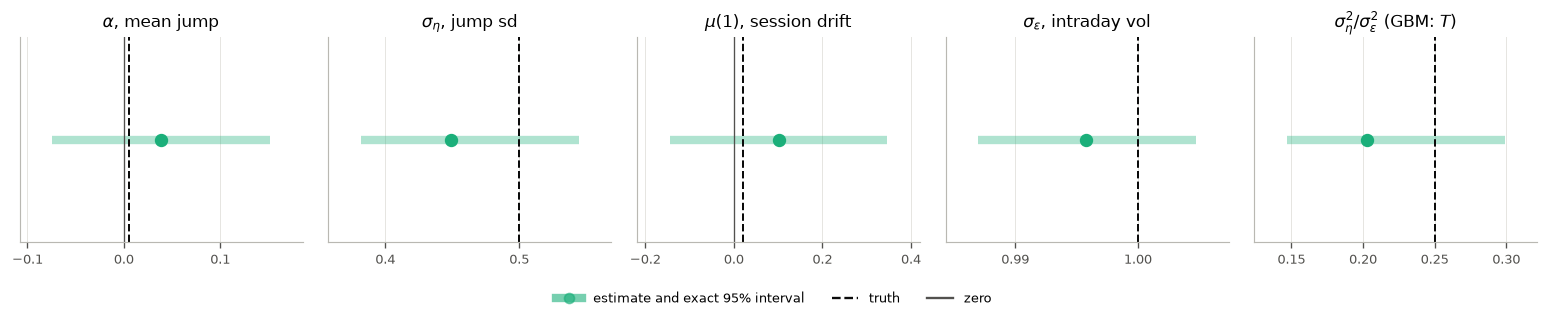

In [8]:
rows = [("alpha", r"$\alpha$, mean jump"), ("sigma_eta", r"$\sigma_\eta$, jump sd"),
        ("mu(1)", r"$\mu(1)$, session drift"), ("sigma_eps", r"$\sigma_\varepsilon$, intraday vol"),
        ("sigma_eta^2/sigma_eps^2", r"$\sigma_\eta^2/\sigma_\varepsilon^2$ (GBM: $T$)")]
fig, axes = plt.subplots(1, len(rows), figsize=(13, 2.4))
for ax, (key, label) in zip(axes, rows):
    est, lo, hi, true = table.loc[key, ["estimate", "lower", "upper", "truth"]]
    mean_param = key in ("alpha", "mu(1)")
    ax.plot([lo, hi], [0, 0], color=FIT, lw=5, alpha=0.35, solid_capstyle="butt")
    ax.plot(est, 0, "o", color=FIT, ms=7)
    ax.axvline(true, color=style.INK, lw=1.2, ls="--")
    if mean_param:                                      # a mean's interval is judged against zero
        ax.axvline(0, color=style.MUTED, lw=0.8)
    left, right = min(lo, true, 0 if mean_param else lo), max(hi, true)
    pad = 0.15 * (right - left)
    ax.set_xlim(left - pad, right + pad)
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_title(label)
    ax.locator_params(axis="x", nbins=4)
fig.legend(handles=[plt.Line2D([], [], color=FIT, marker="o", lw=5, alpha=0.6,
                               label="estimate and exact 95% interval"),
                    plt.Line2D([], [], color=style.INK, ls="--", label="truth"),
                    plt.Line2D([], [], color=style.MUTED, label="zero")],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
style.save_figure(fig, "basic_jump_parameters")
plt.show()

**Every interval covers its truth**, so the fit and the simulator agree. What the table shows
is how differently the two halves of the model are pinned down.

- **The volatility is pinned down.** $s_\varepsilon = 0.9958$ against a true 1, with a relative
  standard error of 0.45% and an interval of $[0.9870, 1.0047]$. It has $(n-1)K = 24{,}180$
  degrees of freedom, because every one-minute increment of every day is information about
  $\sigma_\varepsilon$. More bars a day would sharpen it further without adding a single day.
  That is in-fill estimation: as the grid gets finer, the quadratic variation of even a
  single path recovers $\sigma_\varepsilon$ exactly.
- **The means are barely pinned down.** They are identified, and consistently estimated as
  days accumulate, but only days sharpen them. $\hat\alpha = 0.0386$ and $\hat\mu(1) = 0.1008$
  have t-statistics of 0.68 and 0.80 against zero. Their intervals, $[-0.0744, 0.1516]$ and
  $[-0.1451, 0.3467]$, cover zero, the truth, and five times the truth. The standard error of
  $\hat\mu(1)$ is $\sigma_\varepsilon/\sqrt n$ however finely the day is sampled. For the true
  session drift to sit two standard errors from zero would take 10,000 days, about forty
  years.
- **The GBM's cross-restriction is consistent with the data, and only weakly tested.**
  $s_\eta^2/s_\varepsilon^2 = 0.2031$ against $T = 0.25$, inside $[0.1469, 0.2990]$. The
  interval is wide because the 62 degrees of freedom of the jumps, not the 24,180 of the
  curves, limit it.

For the basic model this means that $\beta$ cannot be found through the level of the jump's
mean, which three months cannot tell from zero. It has to be found through the share of the
jump's *variance* that yesterday's curve explains.

## 4. The fitted model against the data

Three pictures, each setting what the fitted null says beside what the data did.

1. **The curves.** All 63 curves, with the fitted mean $\hat\mu(s)$ and the fitted 95%
   *predictive* band for a new curve, $\hat\mu(s) \pm t\, s_\varepsilon \sqrt{s(1 + 1/n)}$ --
   the band a new day should stay inside 95% of the time at each $s$, widening as $\sqrt s$
   because a Brownian motion's variance grows linearly. The truth (ink, dashed) is drawn on
   top. The right panel zooms in on the mean alone, with its 95% interval, because on the
   scale of the band the mean is invisible.
2. **The data beside a draw from the fitted model.** If the null is right, the two should be
   impossible to tell apart by eye.
3. **The jumps.** Their histogram against the fitted and the true normal densities, a QQ plot
   with a simulated 95% envelope, and the jump series against the fitted 95% prediction
   interval.

Colour carries one meaning per figure: green is the fitted model, ink the truth, grey the
data, and blue and orange the direction of a jump.

interval for mu(s) excludes the truth at minutes [1, 3], and zero at minutes [1, 3], of 390


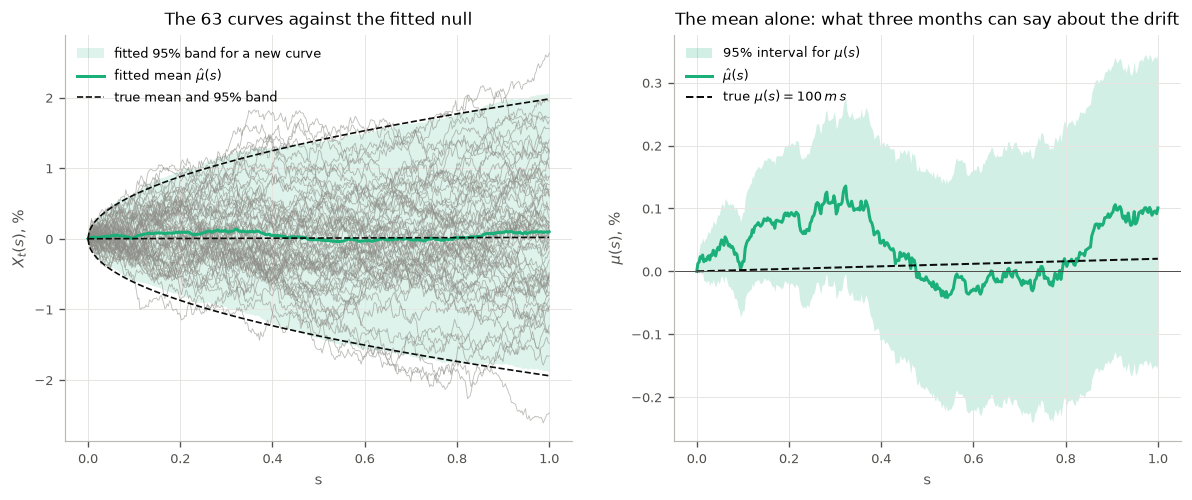

In [9]:
band = be.predictive_band(fit)
true_mu = truth["drift"] * grid
true_half = stats.norm.ppf(0.975) * truth["sigma_eps"] * np.sqrt(grid)
minute = np.round(grid * n_bars).astype(int)
def missed(v):
    # Minutes of the session at which the pointwise 95% interval for mu(s) excludes v.
    return minute[(v < fit["mu_ci"][0]) | (v > fit["mu_ci"][1])].tolist()
print(f"interval for mu(s) excludes the truth at minutes {missed(true_mu)}, "
      f"and zero at minutes {missed(np.zeros_like(grid))}, of {n_bars}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for x in X:
    ax1.plot(grid, x, color=style.CONTROL, lw=0.5, alpha=0.6)
ax1.fill_between(grid, band["lower"], band["upper"], color=FIT, alpha=0.15, lw=0,
                 label="fitted 95% band for a new curve")
ax1.plot(grid, fit["mu"], color=FIT, lw=1.8, label=r"fitted mean $\hat\mu(s)$")
ax1.plot(grid, true_mu, color=style.INK, lw=1.0, ls="--", label=r"true mean and 95% band")
for sign in (-1, 1):
    ax1.plot(grid, true_mu + sign * true_half, color=style.INK, lw=1.0, ls="--")
ax1.set_title("The 63 curves against the fitted null")
ax1.set_xlabel("s")
ax1.set_ylabel(r"$X_t(s)$, %")
ax1.legend(loc="upper left")

ax2.fill_between(grid, *fit["mu_ci"], color=FIT, alpha=0.2, lw=0,
                 label=r"95% interval for $\mu(s)$")
ax2.plot(grid, fit["mu"], color=FIT, lw=1.8, label=r"$\hat\mu(s)$")
ax2.plot(grid, true_mu, color=style.INK, lw=1.2, ls="--", label=r"true $\mu(s) = 100\,m\,s$")
ax2.axhline(0, color=style.MUTED, lw=0.6)
ax2.set_title("The mean alone: what three months can say about the drift")
ax2.set_xlabel("s")
ax2.set_ylabel(r"$\mu(s)$, %")
ax2.legend(loc="upper left")
style.save_figure(fig, "basic_jump_fitted_curves")
plt.show()

**Left.** The curves fill the fitted band the way a Brownian motion should, with the spread
growing like $\sqrt s$. The fitted band and the true band (dashed) are almost the same line,
because the band is set by $\sigma_\varepsilon$, which the data pin down. **Right.** The fitted
mean is another matter. $\hat\mu(s)$ is the average of 63 Brownian paths, so it is itself a
Brownian motion with volatility $\sigma_\varepsilon/\sqrt{63}$. It wanders to above 0.1% and
back, inside an interval that is about $\pm 0.25$ wide by the close. The true drift line and
zero both lie inside that interval at every minute but the first and the third, where the
opening increments happened to run high. The interval is pointwise, so over 390 grid points
a few misses are no surprise. Leaving $\mu$ free costs 390 parameters to
describe noise; section 5's F test asks whether a line would do.

up-jumps: 36 in the data, 35 in the draw


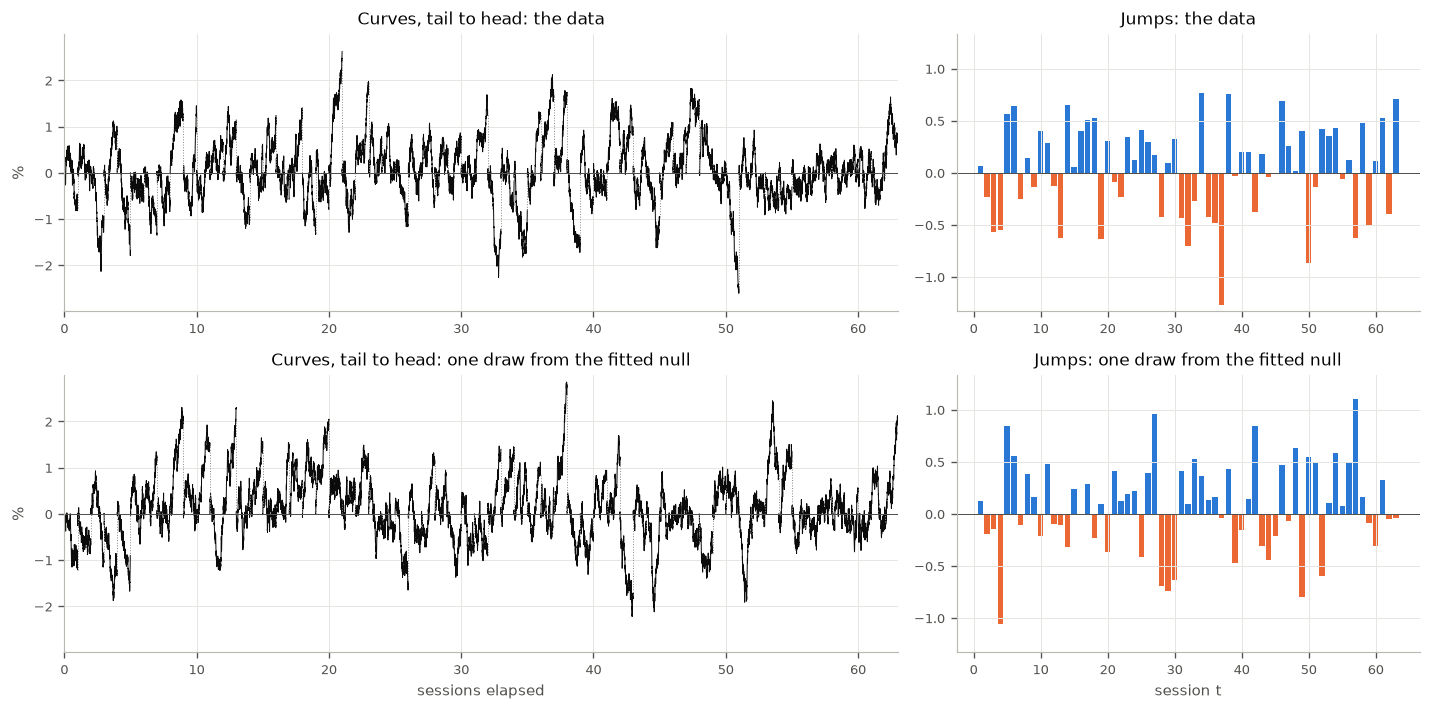

In [10]:
J_model, X_model = be.simulate_null(fit, n_days, rng=np.random.default_rng(2))
print(f"up-jumps: {(J >= 0).sum()} in the data, {(J_model >= 0).sum()} in the draw")
lim_x = 1.05 * max(np.abs(X).max(), np.abs(X_model).max())
lim_j = 1.05 * max(np.abs(J).max(), np.abs(J_model).max())

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharey="col",
                         gridspec_kw={"width_ratios": [1.8, 1]})
for row, (jumps, curves, who) in enumerate(((J, X, "the data"),
                                            (J_model, X_model, "one draw from the fitted null"))):
    tail_to_head(axes[row, 0], curves, grid)
    axes[row, 0].set_ylim(-lim_x, lim_x)
    axes[row, 0].set_title(f"Curves, tail to head: {who}")
    axes[row, 0].set_ylabel("%")
    axes[row, 1].bar(day, jumps, color=np.where(jumps >= 0, UP, DOWN), width=0.8)
    axes[row, 1].axhline(0, color=style.MUTED, lw=0.6)
    axes[row, 1].set_ylim(-lim_j, lim_j)
    axes[row, 1].set_title(f"Jumps: {who}")
axes[1, 0].set_xlabel("sessions elapsed")
axes[1, 1].set_xlabel("session t")
fig.tight_layout()
style.save_figure(fig, "basic_jump_data_vs_draw")
plt.show()

The data and a draw from the fitted model look alike: excursions of the same size, the same
widening through each session, and jumps of the same scale with no runs. This is the check by
eye that the null is an adequate description of these data. On market data it is where
volatility clustering would first show, as quiet stretches of days next to wild ones. The two even have
almost the same number of up-jumps, 36 in the data and 35 in the draw.

standardised jumps outside the pointwise envelope: 2 of 63, at ranks [41, 63] from the bottom


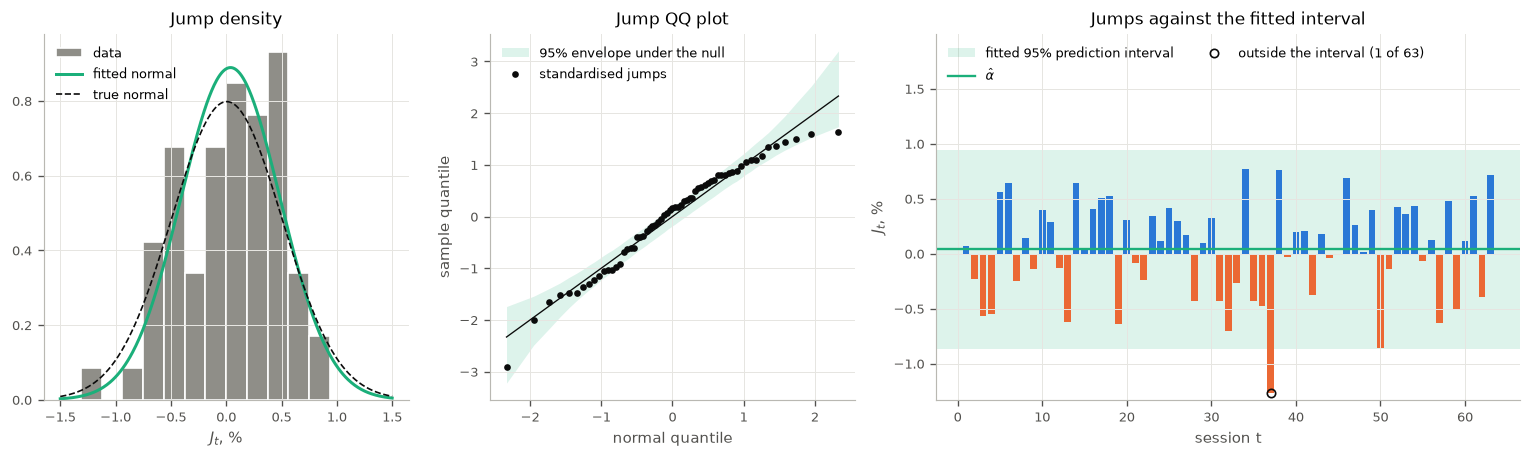

In [11]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.9),
                                    gridspec_kw={"width_ratios": [1, 1, 1.6]})
xs = np.linspace(-edge, edge, 400)
ax1.hist(J, bins=np.linspace(-edge, edge, 17), density=True, color=style.CONTROL,
         edgecolor=style.SURFACE, label="data")
ax1.plot(xs, stats.norm.pdf(xs, fit["alpha"], fit["sigma_eta"]), color=FIT, lw=1.8,
         label="fitted normal")
ax1.plot(xs, stats.norm.pdf(xs, truth["alpha"], truth["sigma_eta"]), color=style.INK, lw=1.0,
         ls="--", label="true normal")
ax1.set_title("Jump density")
ax1.set_xlabel(r"$J_t$, %")
ax1.legend(loc="upper left")

# QQ plot of the standardised jumps, with a pointwise 95% envelope from 4000 normal samples of
# the same size, so that the tails are judged against what n = 63 normals actually do.
z = np.sort((J - fit["alpha"]) / fit["sigma_eta"])
q = stats.norm.ppf((np.arange(1, n_days + 1) - 0.375) / (n_days + 0.25))   # Blom positions
sims = np.sort(np.random.default_rng(3).standard_normal((4000, n_days)), axis=1)
sims = (sims - sims.mean(axis=1, keepdims=True)) / sims.std(axis=1, ddof=1, keepdims=True)
lo, hi = np.quantile(sims, [0.025, 0.975], axis=0)
off = (z < lo) | (z > hi)
print(f"standardised jumps outside the pointwise envelope: {off.sum()} of {n_days}, "
      f"at ranks {(np.flatnonzero(off) + 1).tolist()} from the bottom")
ax2.fill_between(q, lo, hi, color=FIT, alpha=0.15, lw=0, label="95% envelope under the null")
ax2.plot(q, q, color=style.INK, lw=0.8)
ax2.plot(q, z, "o", ms=3, color=style.INK, label="standardised jumps")
ax2.set_title("Jump QQ plot")
ax2.set_xlabel("normal quantile")
ax2.set_ylabel("sample quantile")
ax2.legend(loc="upper left")

ax3.axhspan(*band["jump"], color=FIT, alpha=0.15, lw=0, label="fitted 95% prediction interval")
ax3.axhline(fit["alpha"], color=FIT, lw=1.4, label=r"$\hat\alpha$")
ax3.bar(day, J, color=np.where(J >= 0, UP, DOWN), width=0.8)
outside = (J < band["jump"][0]) | (J > band["jump"][1])
ax3.plot(day[outside], J[outside], "o", ms=5, mfc="none", color=style.INK,
         label=f"outside the interval ({outside.sum()} of {n_days})")
ax3.set_title("Jumps against the fitted interval")
ax3.set_xlabel("session t")
ax3.set_ylabel(r"$J_t$, %")
ax3.set_ylim(-lim_j, 1.5 * lim_j)                   # headroom for the legend
ax3.legend(loc="upper left", ncol=2)
fig.tight_layout()
style.save_figure(fig, "basic_jump_jump_fit")
plt.show()

The fitted normal is a little taller and narrower than the true one because
$s_\eta = 0.4487$ falls below $\sigma_\eta = 0.5$, which is well inside its interval. In the QQ
plot two of the 63 standardised jumps fall just outside the simulated envelope, both in the
right tail: the 41st from the bottom sits a hair above it, and the largest jump below it. The
largest positive jumps all sit below the line, a mildly light right tail that Shapiro-Wilk
weighs in section 5 and does not reject (p = 0.1155). The envelope is pointwise, so about
three of 63 points are expected outside it by chance. One jump of 63 falls outside the fitted 95% prediction interval, where about three
would be expected. In-sample coverage runs high because the interval was fitted to these same
jumps.

## 5. Diagnostics and goodness of fit

The figures in section 4 can only show a misfit that is visible. Each assumption the null
makes is tested here separately, so that a failure says *which* assumption failed rather than
only that something did. Every test is chosen to be exact, or well calibrated, at three
months of data.

| check | assumption of the null | test | why this test |
|---|---|---|---|
| jumps normal | $\eta_t$ is Gaussian | Shapiro-Wilk [[76]](../docs/references.md#ref-shapiro-wilk-1965); Jarque-Bera [[50]](../docs/references.md#ref-jarque-bera-1987) | Shapiro-Wilk is the most powerful standard omnibus test at small $n$; Jarque-Bera reads the same departure as skewness and kurtosis |
| jumps independent | $\eta_t$ independent over days | Ljung-Box [[57]](../docs/references.md#ref-ljung-box-1978) on $J_t$ | serial correlation in the mean |
| squared jumps independent | the same, in the variance | Ljung-Box on $J_t^2$ | volatility clustering, which real overnight moves have |
| jump vs session | $J_t$ independent of $X_t$ | t-test of $\mathrm{corr}(J_t, X_t(1))$ | exact under normality. The *lagged* relation is the basic model's question and is left for it |
| constant volatility | $\sigma_\varepsilon$ does not vary with $s$ | Bartlett [[9]](../docs/references.md#ref-bartlett-1937), across half-hour buckets | real sessions are U-shaped [[1]](../docs/references.md#ref-andersen-bollerslev-1997), and this is where it would show |
| independent increments | $W_t$ has independent increments | lag-1 autocorrelation of the residual increments, z-test | microstructure noise in real prices makes this negative |
| Gaussian increments | $W_t$ has Gaussian increments | Jarque-Bera on the standardised increments | intraday returns are fat-tailed |
| Brownian covariance | $\mathrm{Cov}(X_t(s), X_t(s')) = \sigma_\varepsilon^2\min(s, s')$ | Hilbert-Schmidt distance from the fitted Brownian covariance, Monte Carlo | the distance is invariant to $\mu$ and $\sigma_\varepsilon$, so simulating standard Brownian motion gives an exact test of the curve's whole second-order structure |
| linear drift | $\mu(s) = \mu(1)s$, as the GBM implies | F test of $\Delta\mu_k = c\,\Delta s_k$ | exact on $(K - 1, (n-1)K)$ degrees of freedom; the null does not need it, the GBM does |
| curves independent | $X_t$ independent over days | Gabrys-Kokoszka portmanteau [[29]](../docs/references.md#ref-gabrys-kokoszka-2007) | the functional analogue of Ljung-Box, on the leading principal component scores |

**Thirteen tests at 5% will flag a correct model often**, so each row also carries Holm's
[[41]](../docs/references.md#ref-holm-1979) adjusted p-value, which keeps the chance of *any*
false rejection at 5% whatever the dependence between the tests. The verdict column is read
from it; the cell after the table measures how much that matters.

| setting | value | why |
|---|---|---|
| `n_buckets` | 13 | half-hour buckets of a 6.5-hour session, each with $(n-1) \times 30 = 1860$ degrees of freedom |
| `lags` | 5 and 10 | a week and a fortnight of sessions |
| `n_components` | 4 | the portmanteau test projects onto 4 principal components, which carry 95% of a Brownian curve's variance (the first alone 81%) |
| `portmanteau_lag` | 5 | a week of sessions, with $4^2 \times 5 = 80$ degrees of freedom from 63 curves |
| `n_boot` | 999 | Monte Carlo draws for the covariance test; p-values in steps of one in a thousand |
| seed | 1 | fixes the Monte Carlo draws, so the table reproduces |

In [12]:
diag = be.null_diagnostics(fit, J, X, n_buckets=13, lags=(5, 10), n_components=4,
                           portmanteau_lag=5, n_boot=999, rng=np.random.default_rng(1))
r = np.corrcoef(J, X[:, -1])[0, 1]
print(f"corr(J_t, X_t(1)) = {r:.4f}; the table reports its t-statistic, on {n_days - 2} "
      f"degrees of freedom")
diag["verdict"] = np.where(diag["p_holm"] <= 0.05, "REJECT", "pass")
diag[["check", "test", "statistic", "reference", "p_value", "p_holm", "verdict"]].round(4)

corr(J_t, X_t(1)) = -0.0078; the table reports its t-statistic, on 61 degrees of freedom


,check,test,statistic,reference,p_value,p_holm,verdict
0,jumps normal,Shapiro-Wilk W,0.9692,W under normality,0.1155,1.0000,pass
1,jumps normal,Jarque-Bera,2.7411,chi2(2),0.2540,1.0000,pass
2,jumps independent,"Ljung-Box, 5 lags",3.3597,chi2(5),0.6447,1.0000,pass
3,jumps independent,"Ljung-Box, 10 lags",7.2966,chi2(10),0.6972,1.0000,pass
4,squared jumps independent,"Ljung-Box, 5 lags",1.9572,chi2(5),0.8550,1.0000,pass
5,squared jumps independent,"Ljung-Box, 10 lags",9.2040,chi2(10),0.5129,1.0000,pass
6,jump vs session,"t-statistic of corr(J_t, X_t(1))",-0.0611,t(61),0.9515,1.0000,pass
7,constant volatility,"Bartlett, 13 buckets",8.7740,chi2(12),0.7221,1.0000,pass
8,independent increments,"lag-1 autocorrelation, z-test",-0.6502,"N(0, 1)",0.5156,1.0000,pass
9,Gaussian increments,Jarque-Bera,2.1224,chi2(2),0.3460,1.0000,pass


**Every check passes once the multiple testing is accounted for.** Two raw p-values fall
under 5%:

- **linear drift**, at 0.0356;
- **curves independent** (the portmanteau test), at 0.0239.

Neither is a real failure. The data are a GBM, whose drift is exactly linear and whose days
are exactly independent. The Holm-adjusted values, 0.4276 and 0.3101, say these are what
thirteen tests produce. The first reflects the wander of $\hat\mu$ seen in section 4. The
second matches the lag-3 bump in the autocorrelation of the curves in the figure below.

The other checks are not close to rejecting, from the jump's normality (Shapiro-Wilk 0.1155)
to the Brownian covariance (0.8510). The jump is uncorrelated with its own session: the
correlation is $-0.0078$, the table's $-0.0611$ is its $t$-statistic, and the p-value is
0.9515. That is the contemporaneous half of the null's independence; the lagged half is the basic
model's question. The next cell measures how often a correct model fails a raw test, which is
what makes a "pass" mean something.

In [13]:
# How often does a model that is exactly right fail a check? Simulate 200 fresh quarters from
# the GBM of section 1 -- the true null, with its linear drift -- and run every diagnostic on
# each. (Not from the fitted null: its mean is the free mu_hat, which carries this sample's
# noise, so data drawn from it fail the linear-drift test by construction.) The covariance
# test uses 19 draws here, so the cell runs in about a minute. Its Monte Carlo p-value,
# (1 + k) / (19 + 1), is never below 0.05, and it is exact at 5% when p <= 0.05 counts as a
# rejection -- the rule for any Monte Carlo p-value. With p < 0.05 it could never reject,
# and the rates below would describe twelve tests, not thirteen.
mc_rng = np.random.default_rng(4)
reps, raw_any, holm_any, n_raw = 200, 0, 0, []
for _ in range(reps):
    sim = bd.gbm_sessions(n_days=n_days, n_bars=n_bars, S0=S0, sigma=sigma, T=T, nu=nu,
                          rng=mc_rng)
    J_sim, X_sim = bd.split_sessions(sim["S"], S0)
    d = be.null_diagnostics(be.fit_null(J_sim, X_sim, grid), J_sim, X_sim, n_boot=19,
                            rng=mc_rng)
    n_raw.append(int((d["p_value"] <= 0.05).sum()))
    raw_any += n_raw[-1] > 0
    holm_any += bool((d["p_holm"] <= 0.05).any())
print(f"datasets from the null failing at least one raw test at 5%: {raw_any / reps:.0%}")
print(f"... failing at least one Holm-adjusted test at 5%:          {holm_any / reps:.0%}")
print(f"... failing two or more raw tests at 5%:                   "
      f"{np.mean(np.array(n_raw) >= 2):.0%}")
print(f"raw rejections per dataset: mean {np.mean(n_raw):.2f}, at most {max(n_raw)}")

datasets from the null failing at least one raw test at 5%: 42%
... failing at least one Holm-adjusted test at 5%:          5%
... failing two or more raw tests at 5%:                   15%
raw rejections per dataset: mean 0.61, at most 4


Over 200 fresh quarters from the true GBM, 42% fail at least one raw test at 5%, with 0.61
false rejections per dataset on average. Two or more raw failures, as in the table above,
happen in 15% of them: rarer than one, but no warning sign. After the Holm adjustment the
family-wise rate is 5%, as designed, and that verdict is the one that decides. The other
half of calibration, that each check *does* reject the violation it targets, is in
`tests/test_basic_jump.py`. There a U-shaped volatility, GARCH or AR jumps, fat tails,
Ornstein-Uhlenbeck curves, a curved drift, MA increments, AR curves and a jump tied to its
session each fail their own check after the adjustment.

The figure below shows the curve diagnostics as pictures rather than single numbers, with
the band each should fall in when the null holds.

- **Volatility through the session**: each half-hour bucket's variance rate over the pooled
  rate, with its 95% chi-squared band. Flat at 1 under the null; a U on market data.
- **Variance of the curve**: the sample variance of $X_t(s)$ across days against the fitted
  $s_\varepsilon^2 s$, with the pointwise band from $(n-1)\,\widehat{\mathrm{Var}}/\sigma^2 s
  \sim \chi^2_{n-1}$. Linear growth is the Brownian signature.
- **Increment QQ plot**: all 24,570 standardised residual increments against the normal.
- **Autocorrelation of the jumps**, and of their squares, with the $\pm 1.96/\sqrt n$ band.
- **Autocorrelation of the curves**: the Hilbert-Schmidt norm of the lag-$h$ autocovariance
  of the curves over the lag-0 norm (`far.far_est.acf_norms`), with the 95% band from 500
  draws of the fitted null, since this statistic has no textbook reference distribution.
- **Autocorrelation of the increments within a session**, lags 1 to 10 minutes, with the
  $\pm 1.96/\sqrt{(n-1)(K-h)}$ band.

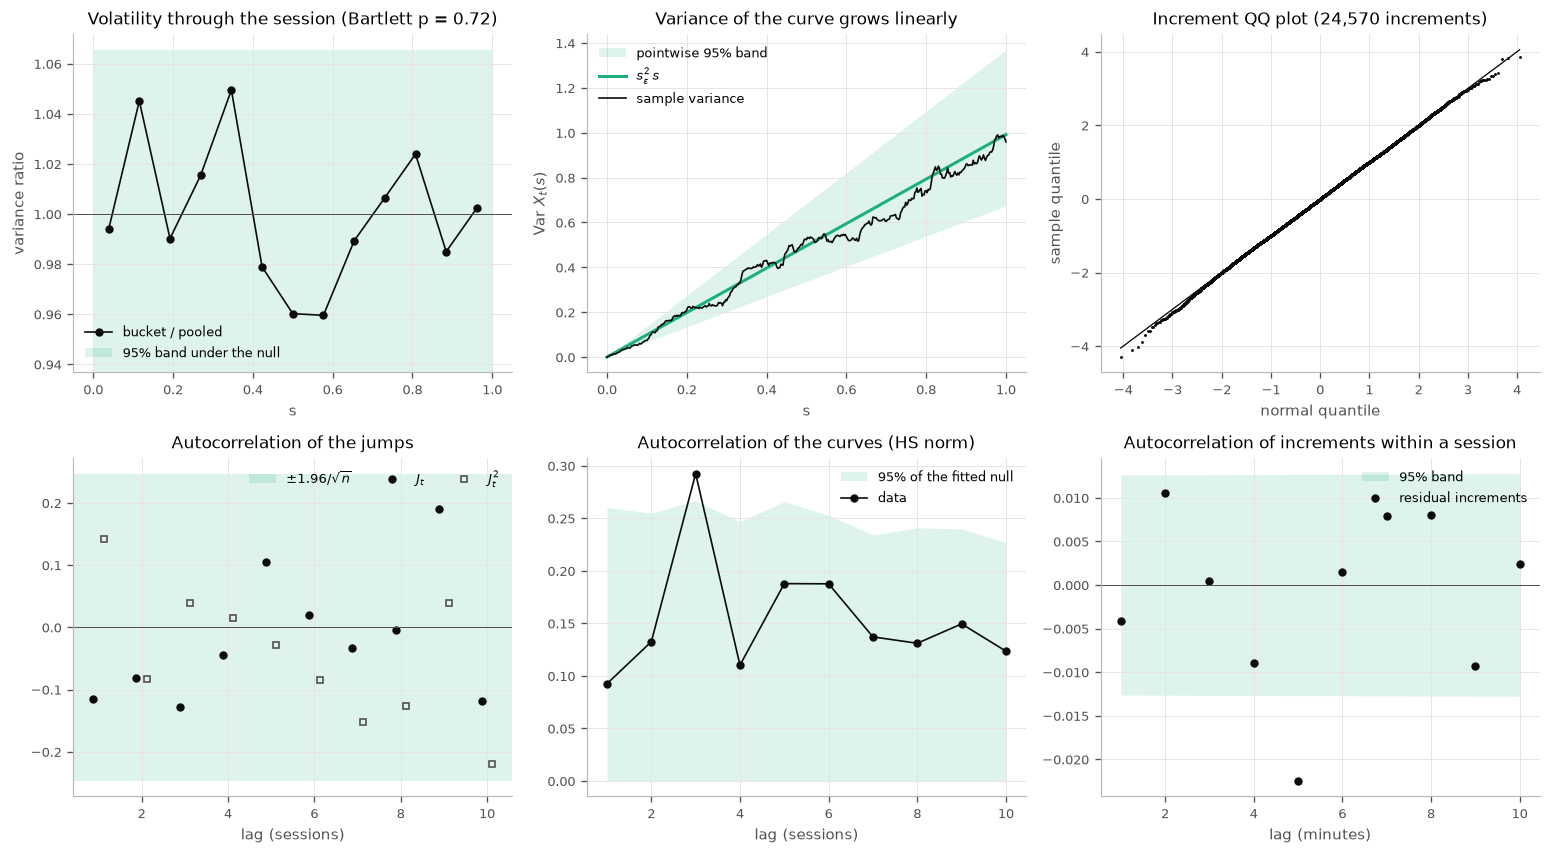

In [14]:
K = fit["K"]
ds = np.diff(grid)
u = (np.diff(X, axis=1) - fit["dmu"]) / np.sqrt(ds)        # residual increments per unit time
buckets = be.bucket_variances(fit, n_buckets=13)
lags = np.arange(1, 11)

fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))

ax = axes[0, 0]
mid = 0.5 * (buckets["start"] + buckets["end"])
width = (buckets["end"] - buckets["start"]).to_numpy()
ax.bar(mid, buckets["upper"] - buckets["lower"], bottom=buckets["lower"], width=width,
       color=FIT, alpha=0.15, label="95% band under the null")
ax.plot(mid, buckets["ratio"], "o-", color=style.INK, ms=4, lw=1, label="bucket / pooled")
ax.axhline(1, color=style.MUTED, lw=0.6)
p_b = diag.loc[diag["check"] == "constant volatility", "p_value"].iloc[0]
ax.set_title(f"Volatility through the session (Bartlett p = {p_b:.2f})")
ax.set_xlabel("s")
ax.set_ylabel("variance ratio")
ax.legend(loc="lower left")

ax = axes[0, 1]
v_hat = X.var(axis=0, ddof=1)
v_fit = fit["sigma_eps"] ** 2 * grid
ax.fill_between(grid, v_fit * stats.chi2.ppf(0.025, n_days - 1) / (n_days - 1),
                v_fit * stats.chi2.ppf(0.975, n_days - 1) / (n_days - 1),
                color=FIT, alpha=0.15, lw=0, label="pointwise 95% band")
ax.plot(grid, v_fit, color=FIT, lw=1.8, label=r"$s_\varepsilon^2\, s$")
ax.plot(grid, v_hat, color=style.INK, lw=1.0, label="sample variance")
ax.set_title("Variance of the curve grows linearly")
ax.set_xlabel("s")
ax.set_ylabel(r"Var $X_t(s)$")
ax.legend(loc="upper left")

ax = axes[0, 2]
zi = np.sort(be.standardised_increments(fit, X).ravel())
qi = stats.norm.ppf((np.arange(1, zi.size + 1) - 0.375) / (zi.size + 0.25))
ax.plot(qi, qi, color=style.INK, lw=0.8)
ax.plot(qi, zi, ".", ms=1.5, color=style.INK)
ax.set_title(f"Increment QQ plot ({zi.size:,} increments)")
ax.set_xlabel("normal quantile")
ax.set_ylabel("sample quantile")

ax = axes[1, 0]
def acf(x, lags):
    xc = x - x.mean()
    return np.array([xc[:-h] @ xc[h:] for h in lags]) / (xc @ xc)
ax.axhspan(-1.96 / np.sqrt(n_days), 1.96 / np.sqrt(n_days), color=FIT, alpha=0.15, lw=0,
           label=r"$\pm 1.96/\sqrt{n}$")
ax.plot(lags - 0.12, acf(J, lags), "o", color=style.INK, ms=4, label=r"$J_t$")
ax.plot(lags + 0.12, acf(J**2, lags), "s", color=style.MUTED, ms=4, mfc="none",
        label=r"$J_t^2$")
ax.axhline(0, color=style.MUTED, lw=0.6)
ax.set_title("Autocorrelation of the jumps")
ax.set_xlabel("lag (sessions)")
ax.legend(loc="upper right", ncol=3)

ax = axes[1, 1]
null_rng = np.random.default_rng(5)
null_acf = np.array([acf_norms(be.simulate_null(fit, n_days, rng=null_rng)[1], grid, max_lag=10)
                     for _ in range(500)])
ax.fill_between(lags, 0, np.quantile(null_acf, 0.95, axis=0), color=FIT, alpha=0.15, lw=0,
                label="95% of the fitted null")
ax.plot(lags, acf_norms(X, grid, max_lag=10), "o-", color=style.INK, ms=4, lw=1,
        label="data")
ax.set_title("Autocorrelation of the curves (HS norm)")
ax.set_xlabel("lag (sessions)")
ax.legend(loc="upper right")

ax = axes[1, 2]
r_inc = np.array([(u[:, :-h] * u[:, h:]).sum() / ((n_days - 1) * (K - h)) for h in lags])
r_inc /= fit["sigma_eps"] ** 2
se_inc = 1 / np.sqrt((n_days - 1) * (K - lags))
ax.fill_between(lags, -1.96 * se_inc, 1.96 * se_inc, color=FIT, alpha=0.15, lw=0,
                label="95% band")
ax.plot(lags, r_inc, "o", color=style.INK, ms=4, label="residual increments")
ax.axhline(0, color=style.MUTED, lw=0.6)
ax.set_title("Autocorrelation of increments within a session")
ax.set_xlabel("lag (minutes)")
ax.legend(loc="upper right")
fig.tight_layout()
style.save_figure(fig, "basic_jump_curve_diagnostics")
plt.show()

Each panel sits inside its null band, with the exceptions chance predicts.

- **Volatility through the session** is flat. Every half-hour bucket is within a few percent of
  the pooled rate, and Bartlett's p is 0.72. On market data this panel would be U-shaped.
- **The variance of the curve** grows linearly in $s$, inside its band all the way to the
  close. This is the Brownian signature, and it is what makes $\sqrt s$ the right width for
  the bands in section 4.
- **The increment QQ plot** is straight out to four standard deviations. Fat-tailed intraday
  returns would bend its ends away from the line.
- **The jumps' autocorrelations**, of levels and of squares, are all inside
  $\pm 1.96/\sqrt n$.
- **The curves' autocorrelation** pokes above the pointwise null band at lag 3 alone. That is
  the signal the portmanteau test picked up, and the portmanteau test, which weighs all lags
  at once, does not reject after adjustment. One excursion in ten pointwise comparisons is not
  remarkable.
- **The increments within a session** are uncorrelated at every lag but 5, which falls just
  outside its band. One of ten is again what chance gives, and the formal lag-1 test is far
  from rejecting.

**Goodness of fit.** The null has nothing to predict with, so there is no $R^2$ to report.
What it does have, and what the basic model will be compared against, is:

- the maximised **log-likelihood** of each equation, with its parameter count, and the AIC
  and BIC built from them;
- the **RMSE** of the jump about $\hat\alpha$, which is $s_\eta$ up to the divisor. It is an
  *in-sample* number: the fitted mean has seen the jumps it is scored on;
- the **coverage** of the fitted 95% prediction band: the share of jumps, and of curve points
  with $s > 0$, inside it. Near 95% means the fitted spread is right; in-sample it runs a
  little high.

The curve's log-likelihood is large and positive because it is a density over 24,570
increments, each with a tiny variance; only differences between nested models mean anything.

The three cells after the table turn these into a comparison with the basic model on equal
terms, in three senses.

1. **On the same days.** The basic model regresses $J_t$ on $X_{t-1}$, so it can use only
   $t = 2, \dots, 63$: there is no curve before day 1. A likelihood ratio, an AIC difference or
   an error compares like with like only if the null is scored on the same 62 jumps.
2. **Out of sample, against a forecast.** Out of sample the null forecasts each jump by the
   mean of the jumps before it (`be.expanding_mean_forecast`). From $m$ earlier jumps that
   forecast has root mean squared error $\sigma_\eta\sqrt{1 + 1/m}$, and it, not the in-sample
   RMSE, is what a predictor of the jump has to beat.
3. **With an exact test.** Given the curves, the basic model's jump equation is a Gaussian
   linear regression on the principal component scores of yesterday's curve, with errors
   independent of the scores. When $\beta = 0$ the F statistic for $p$ components is then
   exactly $F_{p,\,62-p-1}$, so the test holds its level at any sample size. The likelihood ratio referred to $\chi^2_p$ is only its large-sample
   version, and `be.lr_test_size` gives its true size.

In [15]:
gof = be.goodness_of_fit(fit, J, X)
gof.round(4)

,loglik,n_params,n_obs,aic,bic,rmse,band_coverage
jump,-38.4060,2,63,80.8121,85.0984,0.4452,0.9841
curve,38731.0974,391,24570,-76680.1949,-73509.4658,0.9717,0.9531


In [16]:
# The basic model regresses J_t on X_{t-1}, so it can use only t = 2, ..., n: there is no
# curve before day 1. The null has to be scored on those same days for a likelihood ratio, an
# AIC or an error to compare like with like. Only the jump row is used; fit_null takes the
# curves too, but the jump equation's numbers do not depend on them.
fit_lag = be.fit_null(J[1:], X[1:], grid)
same_days = pd.DataFrame({"days 1-63": gof.loc["jump"],
                          "days 2-63": be.goodness_of_fit(fit_lag, J[1:], X[1:]).loc["jump"]}).T
same_days = same_days.astype({"n_params": int, "n_obs": int})
same_days[["loglik", "n_params", "n_obs", "aic", "bic", "rmse"]].round(4)

,loglik,n_params,n_obs,aic,bic,rmse
days 1-63,-38.4060,2,63,80.8121,85.0984,0.4452
days 2-63,-38.2903,2,62,80.5806,84.8348,0.4487


In [17]:
# Out of sample, the null forecasts each jump by the mean of the jumps before it. The first 20
# jumps the basic model can use (days 2-21, a month) train the first forecast; the other 42
# days are forecast one at a time, each from every usable jump before it.
oos = be.expanding_mean_forecast(J, first=21, start=1)
print(f"{oos['t'].size} forecasts, of days {oos['t'][0] + 1} to {oos['t'][-1] + 1}")
print(f"out-of-sample RMSE of the expanding mean:       {oos['rmse']:.4f}")
print(f"in-sample RMSE about alpha_hat, days 2-63:       {same_days.loc['days 2-63', 'rmse']:.4f}")
print(f"expected out-of-sample RMSE under the true null: {truth['sigma_eta'] * oos['inflation']:.4f}"
      f" (sigma_eta times {oos['inflation']:.4f})")

42 forecasts, of days 22 to 63
out-of-sample RMSE of the expanding mean:       0.4630
in-sample RMSE about alpha_hat, days 2-63:       0.4487
expected out-of-sample RMSE under the true null: 0.5068 (sigma_eta times 1.0136)


In [18]:
# The likelihood-ratio test of beta = 0 with p components, referred to chi-squared(p), on the
# 62 days the basic model can use: its true size, from the exact F distribution of the same
# statistic. The F test is exact, so its size is the nominal 5%.
components = [1, 2, 4, 8]
pd.DataFrame({"size of the chi2 LR test": [be.lr_test_size(n_days - 1, p) for p in components],
              "size of the F test": 0.05},
             index=pd.Index(components, name="components p")).round(4)

,size of the chi2 LR test,size of the F test
components p,,
1,0.0548,0.05
2,0.0578,0.05
4,0.0644,0.05
8,0.0823,0.05


These are the numbers the basic model inherits.

- **The jump equation's log-likelihood** on all 63 days is $-38.4060$, from 2 parameters, with
  AIC 80.8121. On days 2-63, the days the basic model can use, it is $-38.2903$, with AIC
  80.5806 and BIC 84.8348, and these are the values to compare with. On those days
  $2(\ell_{\text{basic}} - \ell_{\text{null}})$ is the likelihood-ratio statistic for
  $\beta = 0$.
- **The test of $\beta = 0$** should be the exact F test. At 62 days the $\chi^2_p$ reference
  rejects a true null 5.5% of the time with one component, 6.4% with four and 8.2% with eight.
  The excess is modest for a few components, but it costs nothing to avoid. The F test is
  exact only while the curves are independent of the jump's errors, so it stops being exact
  in v2, where $X_t$ depends on $J_t$.
- **The jump RMSE** in sample is 0.4452 on all 63 days and 0.4487 on days 2-63. The
  out-of-sample benchmark is the expanding mean's RMSE over the 42 forecast days, days 22-63:
  0.4630. Under the true null it would be about $0.5 \times 1.0136 = 0.5068$; here it comes in
  lower, because this sample's jumps are calmer than the truth ($s_\eta = 0.4487$ against
  $\sigma_\eta = 0.5$). A forecast from yesterday's curve has to beat 0.4630 on the same 42
  days.
- **The curve equation** has a log-likelihood of 38731.0974, from 391 parameters. It plays no
  part in the test of $\beta$, because the basic model leaves the curve equation unchanged.
  It will matter when the jump enters the curve, as it does in v2.
- **Band coverage** is 0.9531 for the curve points, which is the nominal 95% to within its
  sampling error, so the fitted spread is right. For the jumps it is 0.9841, one jump outside
  of 63.

## 6. What this establishes, and what comes next

**Established.**

1. **The slicing is exact.** The jumps and session returns rebuild every close with zero
   error. `tests/test_basic_jump.py` shows the same pairs come out of the `fdaSP.intraday`
   pipeline that market data will go through.
2. **The null model fits a GBM as it should.** Every parameter's exact interval covers the
   truth, every diagnostic passes after the Holm adjustment, and the two raw failures are no
   warning sign: at this design a correct model fails at least one raw test 42% of the time,
   and two or more 15% of the time.
3. **The two halves of the model are estimated with very different precision.** Three
   months fix the curve's volatility to under half a percent, and they cannot tell the mean jump, or the
   session's drift, from zero. A larger grid sharpens the first and does nothing for the
   second.

**What that means for the basic model.** The research hypothesis puts
$\int_0^1 \beta(u)X_{t-1}(u)\,\mathrm{d}u$ into the jump equation. Every term it adds has to
earn its place against the baseline above:

- on days 2-63, the jump log-likelihood of $-38.2903$, through the exact F test of
  $\beta = 0$;
- out of sample, the expanding mean's RMSE of 0.4630 over days 22-63.

Because a quarter cannot even tell the jump's unconditional mean from zero, $\beta$ can only
be detected through the share of the jump's *variance* it explains. Over 63 days only a large
$\beta$ will be visible.

**Next step.**

1. Simulate the basic model with a known $\beta \ne 0$.
2. Fit $\beta(u)$ by principal-component regression on the scores of yesterday's curve, the
   machinery `jump.jump_eq.fit_mle` already provides.
3. Test it against this null with the exact F test on days 2-63, and compare its
   out-of-sample forecasts with the expanding mean's on days 22-63.
4. Measure the test's power as a function of the size of $\beta$ and the length of the
   sample, which gives the honest answer to how much data the research question needs.